# Módulo 09: Morfología Litoral y Erosión de Dunas (`sedmor.littoral`)

Este cuaderno reúne las herramientas costeras de transporte longitudinal de sedimentos y erosión de dunas bajo tormenta basadas en los modelos analíticos y paramétricos de **van Rijn**, **Kamphuis**, **CERC**, **Kriebel & Dean** y **Hallermeier & Rhodes**.

### Objetivos de aprendizaje
1. Comparar las tasas de **transporte longitudinal litoral** ($Q_t$) entre van Rijn, Kamphuis y CERC frente al ángulo de incidencia y al diámetro de grano $d_{50}$ (`longshore_and_dune_erosion`).
2. Calcular el **balance anual neto y bruto de deriva litoral** en costas con clima de oleaje bidireccional (`annual_longshore_transport`, `wrap_wave_angle_to_normal`).
3. Cuantificar el **volumen erosionado y el retroceso de dunas** durante marejadas ciclónicas (`ssl`) y temporales extremos.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Transporte Longitudinal por Tormenta y Sensibilidad al Ángulo de Incidencia

Evaluamos el transporte sólido longitudinal para una tormenta ($H_{s,0} = 4.0\,\text{m}$, $T_p = 11\,\text{s}$, arena media $d_{50} = 0.25\,\text{mm}$) variando el ángulo de incidencia $\theta_0$ desde $0^\circ$ hasta $70^\circ$.


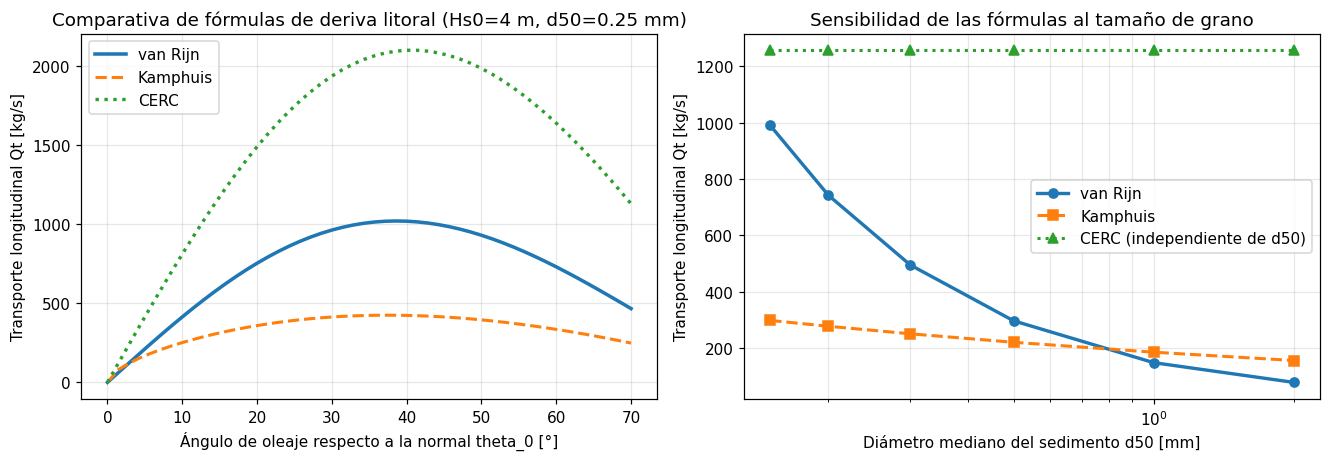

In [2]:
angles = np.linspace(0.0, 70.0, 50)
storm = sm.littoral.longshore_and_dune_erosion(
    depth_offshore=25.0, d50=0.00025, tan_beta=0.015, gamma_br=0.6,
    wave_height_offshore=4.0, wave_period=11.0, swell_period=6.0,
    wave_angle_offshore=angles, v_tide=0.0, hwl=1.0, ssl=3.0, dune_height=5.0, duration_hours=12.0
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.3))

ax1.plot(angles, storm.qt_van_rijn_kg_s, lw=2.3, label="van Rijn")
ax1.plot(angles, storm.qt_kamphuis_kg_s, "--", lw=2.0, label="Kamphuis")
ax1.plot(angles, storm.qt_cerc_kg_s, ":", lw=2.2, label="CERC")
ax1.set_xlabel("Ángulo de oleaje respecto a la normal theta_0 [°]")
ax1.set_ylabel("Transporte longitudinal Qt [kg/s]")
ax1.set_title("Comparativa de fórmulas de deriva litoral (Hs0=4 m, d50=0.25 mm)")
ax1.grid(alpha=0.3)
ax1.legend()

# Sensibilidad al tamaño de grano (d50) para theta_0 = 25°
d50_vals = np.array([0.00015, 0.0002, 0.0003, 0.0005, 0.001, 0.002])
grain_res = sm.littoral.longshore_and_dune_erosion(
    depth_offshore=25.0, d50=d50_vals, tan_beta=0.015,
    wave_height_offshore=3.5, wave_period=10.0, wave_angle_offshore=25.0
)
ax2.semilogx(d50_vals * 1000, grain_res.qt_van_rijn_kg_s, "o-", lw=2.2, label="van Rijn")
ax2.semilogx(d50_vals * 1000, grain_res.qt_kamphuis_kg_s, "s--", lw=2.0, label="Kamphuis")
ax2.semilogx(d50_vals * 1000, grain_res.qt_cerc_kg_s, "^:", lw=2.0, label="CERC (independiente de d50)")
ax2.set_xlabel("Diámetro mediano del sedimento d50 [mm]")
ax2.set_ylabel("Transporte longitudinal Qt [kg/s]")
ax2.set_title("Sensibilidad de las fórmulas al tamaño de grano")
ax2.grid(alpha=0.3, which="both")
ax2.legend()

plt.tight_layout()
plt.show()


## 2. Balance Anual de Deriva Litoral Bidireccional y Erosión de Dunas

Simulamos una playa orientada con normal costera hacia los $270^\circ\,\text{N}$ sometida a oleaje del sector NW (deriva positiva) y SW (deriva negativa). Luego comparamos el volumen erosionado en un cordón dunar frente al nivel de sobreelevación de tormenta (`ssl`).


Deriva anual neta  -> van Rijn:   +437,782 m³/año | Kamphuis:   +153,791 m³/año
Deriva anual bruta -> van Rijn:  1,551,509 m³/año | Kamphuis:    798,973 m³/año


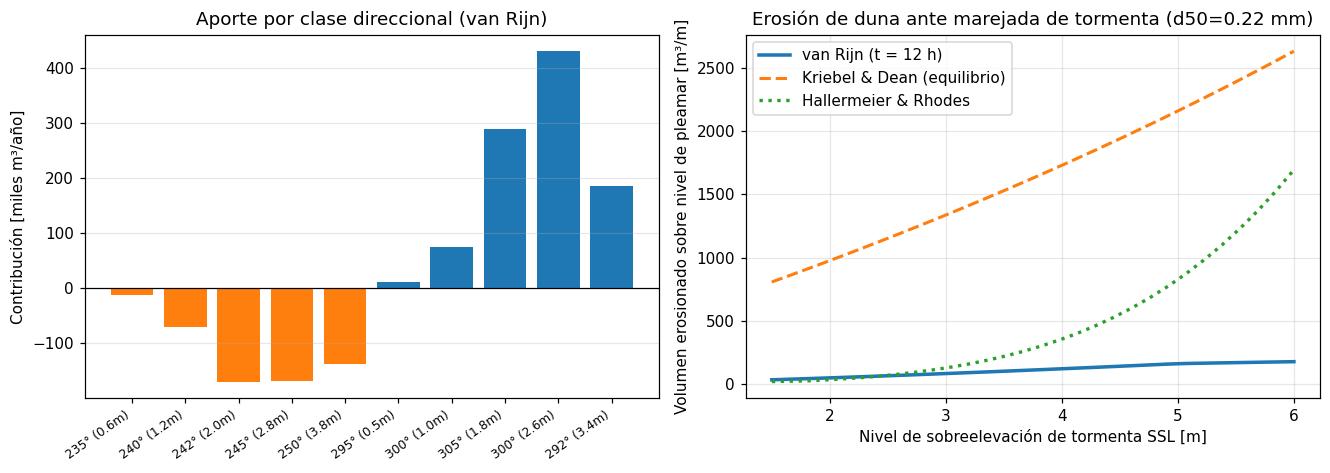

In [3]:
days_cl = np.array([60, 45, 25, 10, 4, 80, 65, 45, 25, 6], dtype=float)
hs_cl = np.array([0.6, 1.2, 2.0, 2.8, 3.8, 0.5, 1.0, 1.8, 2.6, 3.4])
tp_cl = np.array([5.0, 7.0, 9.0, 10.5, 12.0, 5.0, 6.5, 8.5, 10.0, 11.5])
ang_n = np.array([235, 240, 242, 245, 250, 295, 300, 305, 300, 292], dtype=float)

ann = sm.littoral.annual_longshore_transport(
    days=days_cl, wave_height_offshore=hs_cl, wave_period=tp_cl,
    wave_angle_north=ang_n, shore_normal_north=270.0,
    depth_offshore=20.0, d50=0.00022, tan_beta=0.012
)

print(f"Deriva anual neta  -> van Rijn: {ann.van_rijn_net_m3_yr:+10,.0f} m³/año | Kamphuis: {ann.kamphuis_net_m3_yr:+10,.0f} m³/año")
print(f"Deriva anual bruta -> van Rijn: {ann.van_rijn_gross_m3_yr:10,.0f} m³/año | Kamphuis: {ann.kamphuis_gross_m3_yr:10,.0f} m³/año")

# Erosión de dunas frente a nivel máximo de tormenta (SSL)
ssl_range = np.linspace(1.5, 6.0, 30)
dune = sm.littoral.longshore_and_dune_erosion(
    depth_offshore=25.0, d50=0.00022, tan_beta=0.015,
    wave_height_offshore=5.0, wave_period=12.0, wave_angle_offshore=15.0,
    hwl=1.2, ssl=ssl_range, dune_height=6.0, duration_hours=12.0
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))

cl_labels = [f"{int(a)}° ({h:.1f}m)" for a, h in zip(ang_n, hs_cl)]
ax1.bar(np.arange(len(days_cl)), ann.van_rijn_signed_m3 / 1e3, color=["tab:blue" if v >= 0 else "tab:orange" for v in ann.van_rijn_signed_m3])
ax1.axhline(0.0, color="k", lw=0.8)
ax1.set_xticks(np.arange(len(days_cl)))
ax1.set_xticklabels(cl_labels, rotation=35, ha="right", fontsize=8)
ax1.set_ylabel("Contribución [miles m³/año]")
ax1.set_title("Aporte por clase direccional (van Rijn)")
ax1.grid(alpha=0.3, axis="y")

ax2.plot(ssl_range, dune.vr_volume_t, lw=2.3, label="van Rijn (t = 12 h)")
ax2.plot(ssl_range, dune.kd_volume, "--", lw=2.0, label="Kriebel & Dean (equilibrio)")
ax2.plot(ssl_range, dune.hr_volume, ":", lw=2.2, label="Hallermeier & Rhodes")
ax2.set_xlabel("Nivel de sobreelevación de tormenta SSL [m]")
ax2.set_ylabel("Volumen erosionado sobre nivel de pleamar [m³/m]")
ax2.set_title("Erosión de duna ante marejada de tormenta (d50=0.22 mm)")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Analice en `annual_longshore_transport` cómo varía la deriva neta al rotar la orientación normal de la costa `shore_normal_north` entre `255°` y `285°` (equivalente a evaluar un tramo curvo o protegido).
2. Evalúe con `longshore_and_dune_erosion` la sensibilidad del volumen erosionado `vr_volume_t` a la pendiente de playa `tan_beta` entre `0.008` y `0.025`.
